# Importing PyHiM chromatin-trace tables (ECSV)

[PyHiM](https://github.com/pyHi-M/pyHiM) (Devos et al. 2024, *Genome Biology*) analyses
multiplexed DNA-FISH (Hi-M) images and writes its chromatin traces as an **Astropy ECSV**
table (`Spot_ID, Trace_ID, x, y, z, Chrom, Chrom_Start, Chrom_End, ROI #, Mask_id,
Barcode #, label`).  In this tutorial you read such a table with
`ChromData.from_pyhim_trace` (package `chromdata`; needs `astropy`), check it against the
original data, handle a table whose genomic columns are empty (`barcode_dict=`), and take a
first look at the traces with `uchrom.fea` / `uchrom.pl`.

**Data**: Bintu et al. 2018, *Science* 362:eaau1783 — IMR90 chromatin tracing of
chr21:18.6–20.6 Mb (hg38), 1,277 traced chromosomes × 65 segments of 30 kb.  The authors
publish a plain CSV (`IMR90_chr21-18-20Mb.csv`); `example-data/bintu_to_pyhim_ecsv.py`
rewrites it in PyHiM's ECSV schema (`IMR90_chr21_pyhim.ecsv`).  **Runtime**: about 20 s.

In [1]:
from pathlib import Path
import subprocess
import sys
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from chromdata import ChromData
import uchrom.fea as fea

plt.rcParams["figure.dpi"] = 90


def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "example-data" / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the U-Chrom repository")


REPO = find_repo_root(); DATA = REPO / "example-data"; OUT = REPO / "tutorials" / "_out"; OUT.mkdir(exist_ok=True)

BINTU_URL = "https://raw.githubusercontent.com/BogdanBintu/ChromatinImaging/master/Data/IMR90_chr21-18-20Mb.csv"


def find_bintu_csv() -> Path:
    """Bintu 2018 IMR90 chr21 tracing CSV (2 MB, not in git): downloaded once into example-data/."""
    path = DATA / "IMR90_chr21-18-20Mb.csv"
    if not path.exists():
        print("downloading IMR90_chr21-18-20Mb.csv (2 MB) from the authors' GitHub ...")
        urllib.request.urlretrieve(BINTU_URL, path)
    return path


def find_pyhim_ecsv() -> Path:
    """The PyHiM-format ECSV, built from the Bintu CSV by example-data/bintu_to_pyhim_ecsv.py."""
    path = DATA / "IMR90_chr21_pyhim.ecsv"
    if not path.exists():
        find_bintu_csv()
        subprocess.run([sys.executable, str(DATA / "bintu_to_pyhim_ecsv.py")], check=True)
    return path


BINTU = find_bintu_csv()
ECSV = find_pyhim_ecsv()
for p in (BINTU, ECSV):
    print(f"{p.relative_to(REPO)}  ({p.stat().st_size / 1e6:.1f} MB)")

example-data/IMR90_chr21-18-20Mb.csv  (2.0 MB)
example-data/IMR90_chr21_pyhim.ecsv  (5.7 MB)


## 1. What a PyHiM ECSV looks like

An ECSV file starts with a YAML header (`# ` lines): the column names and dtypes and a
`meta` block.  PyHiM's `meta['comments']` carries `key=value` strings such as `xyz_unit`
and `genome_assembly`.  The data rows follow, space-separated.

In [2]:
with open(ECSV) as fh:
    for line in fh.readlines()[:24]:
        print(line.rstrip()[:120])

# %ECSV 1.0
# ---
# datatype:
# - {name: Spot_ID, datatype: string}
# - {name: Trace_ID, datatype: string}
# - {name: x, datatype: float64}
# - {name: y, datatype: float64}
# - {name: z, datatype: float64}
# - {name: Chrom, datatype: string}
# - {name: Chrom_Start, datatype: int64}
# - {name: Chrom_End, datatype: int64}
# - {name: 'ROI #', datatype: int64}
# - {name: Mask_id, datatype: int64}
# - {name: 'Barcode #', datatype: int64}
# - {name: label, datatype: string}
# meta: !!omap
# - comments: [xyz_unit=micron, genome_assembly=hg38, 'source=Bintu et al. 2018 Science 362:eaau1783', 'region=chr21:18.
#     n_traces=1277, mean_spots_per_trace=65.0, segment_spacing=30kb, note=Not all traces have all 66 segments (imaging 
# schema: astropy-2.0
Spot_ID Trace_ID x y z Chrom Chrom_Start Chrom_End "ROI #" Mask_id "Barcode #" label
1_1 1 117.803 58.446 1.733 chr21 18627714 18657714 0 1 1 None
1_2 1 117.726 58.747 1.68 chr21 18657714 18687714 0 1 2 None
1_3 1 117.747 58.607 1.872 chr21 1868771

## 2. Read it with `from_pyhim_trace`

The column mapping: `x, y, z → coords`; `Chrom, Chrom_Start, Chrom_End → ` the locus axis
`bins`; `Trace_ID → trace_id`; `Mask_id → cell_id` (PyHiM's segmentation mask; in this
conversion every chromosome is its own "cell"); `ROI # → roi_id`, `Barcode # → barcode`,
`Spot_ID → spot_id`, `label` stays.  The ECSV comments are kept in `uns['pyhim']`, and
`xyz_unit` / `genome_assembly` are promoted to `uns`.

In [3]:
cd = ChromData.from_pyhim_trace(ECSV)
print(cd)
print()
print("uns['xyz_unit'] =", cd.uns["xyz_unit"], "| uns['genome_assembly'] =", cd.uns["genome_assembly"])
print("ECSV comments:", cd.uns["pyhim"]["ecsv_comments"][:5], "...")
missing = np.isnan(cd.coords[:, 0])
print(f"\n{cd.n_traces:,} traces x {cd.n_bins} loci = {cd.n_spots:,} spots; "
      f"{missing.mean():.1%} of the spots have no coordinates (segment not detected: NaN rows)")
cd.spots.head()

ChromData: n_spots=83005, n_traces=1277, n_cells=1277, n_bins=65
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'roi_id', 'barcode', 'label', 'bin_id']
  uns:     ['pyhim', 'xyz_unit', 'genome_assembly']

uns['xyz_unit'] = micron | uns['genome_assembly'] = hg38
ECSV comments: ['xyz_unit=micron', 'genome_assembly=hg38', 'source=Bintu et al. 2018 Science 362:eaau1783', 'region=chr21:18.6-20.6 Mb', 'cell_type=IMR90'] ...

1,277 traces x 65 loci = 83,005 spots; 6.3% of the spots have no coordinates (segment not detected: NaN rows)


,chrom,start,end,trace_id,spot_id,cell_id,roi_id,barcode,label,bin_id
0,chr21,18627714,18657714,1,1_1,1,0,1,None,0
1,chr21,18657714,18687714,1,1_2,1,0,2,None,1
2,chr21,18687714,18717714,1,1_3,1,0,3,None,2
3,chr21,18717714,18747714,1,1_4,1,0,4,None,3
4,chr21,18747714,18777714,1,1_5,1,0,5,None,4


In [4]:
cd.bins.head()   # 65 loci of 30 kb from chr21:18,627,714

,chrom,start,end
bin_id,,,
0,chr21,18627714,18657714
1,chr21,18657714,18687714
2,chr21,18687714,18717714
3,chr21,18717714,18747714
4,chr21,18747714,18777714


## 3. Check the import against the original CSV

`uchrom.io.read_bintu_tracing` reads the authors' own CSV (coordinates in nm, undetected
segments dropped).  The two imports must hold the same spots: same traces, same loci and the
same coordinates (µm × 1000 = nm).

In [5]:
from uchrom.io import read_bintu_tracing

ref = read_bintu_tracing(BINTU, chrom="chr21", start_bp=18_627_714, resolution_bp=30_000)
print(ref, "\n")

key = ["trace_id", "start"]
a = cd.to_dataframe().dropna(subset=["x"]).astype({"trace_id": str})[key + ["x", "y", "z"]]
b = ref.to_dataframe().astype({"trace_id": str})[key + ["x", "y", "z"]]
m = a.merge(b, on=key, suffixes=("_ecsv", "_csv"), validate="one_to_one")
err = max(np.abs(m[f"{c}_ecsv"] * 1000 - m[f"{c}_csv"]).max() for c in "xyz")
print(f"spots with coordinates: ECSV {len(a):,}, original CSV {len(b):,}, matched {len(m):,}")
print(f"largest coordinate difference: {err:.2e} nm")
assert len(m) == len(a) == len(b) and err < 1e-6

ChromData: n_spots=77797, n_traces=1277, n_cells=1277, n_bins=65
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  uns:     ['xyz_unit', 'genome_assembly', 'source'] 

spots with coordinates: ECSV 77,797, original CSV 77,797, matched 77,797
largest coordinate difference: 1.46e-11 nm


## 4. Tables without genomic coordinates: `barcode_dict=`

PyHiM fills `Chrom` / `Chrom_Start` / `Chrom_End` only when it was given the barcode →
genome mapping; otherwise those columns are empty and only `Barcode #` identifies the locus.
To show this, write a copy of the real table with the three columns blanked, as such a run
would produce it.  Reading it then needs a `barcode_dict` — `{barcode: (chrom, start, end)}`
or a DataFrame with columns `barcode, chrom, start, end` — usually your probe design.

In [6]:
from astropy.table import Table

t = Table.read(ECSV, format="ascii.ecsv")
t["Chrom"] = [""] * len(t)
t["Chrom_Start"] = np.zeros(len(t), dtype=np.int64)
t["Chrom_End"] = np.zeros(len(t), dtype=np.int64)
no_loci = OUT / "IMR90_chr21_pyhim_noloci.ecsv"
t.write(no_loci, format="ascii.ecsv", overwrite=True)

try:
    ChromData.from_pyhim_trace(no_loci)
except ValueError as e:
    print("without barcode_dict:", e)

without barcode_dict: PyHiM ECSV has no Chrom/Chrom_Start/Chrom_End data; pass `barcode_dict={barcode: (chrom, start, end)}` or a DataFrame[barcode, chrom, start, end].


In [7]:
# the probe panel: barcode b covers chr21:18,627,714 + (b - 1) * 30 kb
panel = pd.DataFrame({"barcode": np.arange(1, 66)})
panel["chrom"] = "chr21"
panel["start"] = 18_627_714 + (panel["barcode"] - 1) * 30_000
panel["end"] = panel["start"] + 30_000

cd2 = ChromData.from_pyhim_trace(no_loci, barcode_dict=panel)
pd.testing.assert_frame_equal(cd.to_dataframe(), cd2.to_dataframe())
print("with barcode_dict: same object as the fully annotated table —", cd2.n_spots, "spots,", cd2.n_bins, "loci")

with barcode_dict: same object as the fully annotated table — 83005 spots, 65 loci


## 5. A first look at the traces

The table is now an ordinary `ChromData`, so the feature functions apply.  Per-trace radius of
gyration (`uchrom.fea.radius_of_gyration`), the population median distance map
(`uchrom.fea.distance_map`; missing spots are skipped pair by pair) and one single trace
(`cd.compute_distances(trace_id=...)`).  Bintu et al. saw TAD-like domains in the population
map that are much less regular in single chromosomes.

In [8]:
df = cd.to_dataframe().dropna(subset=["x"])          # skip the undetected segments
rg = fea.radius_of_gyration(df)
print(f"radius of gyration over {rg.notna().sum():,} traces: median {rg.median():.3f} um "
      f"(IQR {rg.quantile(0.25):.3f}-{rg.quantile(0.75):.3f})")

dm = fea.distance_map(cd, "chr21", stat="median")
print(f"median distance map: {dm.matrix.shape}, from {dm.n_traces} traces; "
      f"adjacent loci {np.nanmedian(np.diag(dm.matrix, 1)):.3f} um, "
      f"ends of the region {dm.matrix[0, -1]:.3f} um apart")

radius of gyration over 1,277 traces: median 0.418 um (IQR 0.375-0.476)


median distance map: (65, 65), from 1277 traces; adjacent loci 0.302 um, ends of the region 0.608 um apart


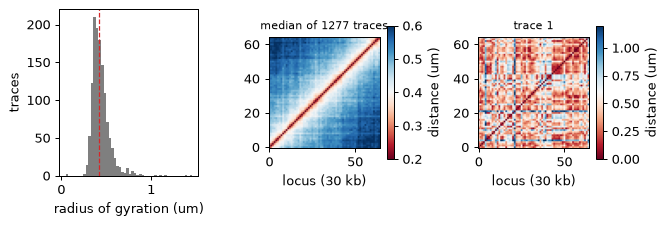

In [9]:
# one fully detected trace (all 65 segments)
n_obs = df.groupby("trace_id", observed=True).size()
tid = n_obs.index[n_obs == cd.n_bins][0]
single = cd.compute_distances(trace_id=tid)

fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.6))
axes[0].hist(rg.dropna(), bins=50, color="tab:gray")
axes[0].axvline(rg.median(), color="tab:red", ls="--", lw=1)
axes[0].set_xlabel("radius of gyration (um)"); axes[0].set_ylabel("traces")
for ax, mat, title, (vmin, vmax) in [(axes[1], dm.matrix, f"median of {dm.n_traces} traces", (0.2, 0.6)),
                                     (axes[2], single, f"trace {tid}", (0, 1.2))]:
    im = ax.imshow(mat, cmap="RdBu", vmin=vmin, vmax=vmax, origin="lower")
    ax.set_title(title, fontsize=9); ax.set_xlabel("locus (30 kb)")
    fig.colorbar(im, ax=ax, shrink=0.8, label="distance (um)")
plt.tight_layout(); plt.show()

## 6. Save

Write the object as a `.chromdata.zarr` store; it keeps everything (including `uns['pyhim']`)
and reads back in a fraction of the ECSV parse time.

In [10]:
store = OUT / "imr90_chr21_pyhim.chromdata.zarr"
cd.write(store)
back = ChromData.read(store)
a = cd.to_dataframe().sort_values(["trace_id", "start"]).reset_index(drop=True)
b = back.to_dataframe().sort_values(["trace_id", "start"]).reset_index(drop=True)
pd.testing.assert_frame_equal(a, b, check_categorical=False)
print(f"wrote {store.relative_to(REPO)}; read back {back.n_spots:,} spots, uns keys {sorted(back.uns)}")

wrote tutorials/_out/imr90_chr21_pyhim.chromdata.zarr; read back 83,005 spots, uns keys ['genome_assembly', 'pyhim', 'xyz_unit']


## Next steps

- `import_fofct.ipynb` — the 4DN FOF-CT format (with cell and RNA tables), and streaming imports.
- `fish_imputation.ipynb` — fill the 6 % undetected segments (this same Bintu table is its
  hold-out benchmark).
- Structure calling on imaging data: `tad_calling.ipynb`, `loop_calling.ipynb`,
  `fishnet_domains.ipynb`; `gem_fish_reconstruction.ipynb` combines this Bintu table with
  IMR90 Hi-C.
- Interactive view: `python -m uchrom_browser tutorials/_out/imr90_chr21_pyhim.chromdata.zarr`.